# Week 2 — Exploratory Data Analysis & ML Model Training
## IPL Auction Price Prediction

**Objective:** Explore auction pricing patterns, train ML models to predict player valuations, and evaluate using temporal train/test splits.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
plt.rcParams['figure.figsize'] = (12, 6)

PROJECT_DIR = '/home/claude/ipl-auction-optimizer'
df = pd.read_csv(f'{PROJECT_DIR}/data/processed/ml_auction_dataset.csv')
print(f'Dataset: {df.shape[0]} records x {df.shape[1]} columns')
print(f'Years: {sorted(df["auction_year"].unique())}')
df['sold_price_cr'].describe().round(2)

Dataset: 1279 records x 31 columns
Years: [np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2025)]


count    1279.00
mean        2.65
std         3.84
min         0.10
25%         0.30
50%         1.00
75%         3.25
max        27.00
Name: sold_price_cr, dtype: float64

## 1. Price Distribution
IPL auction prices are heavily right-skewed — most players sell at or near base price.

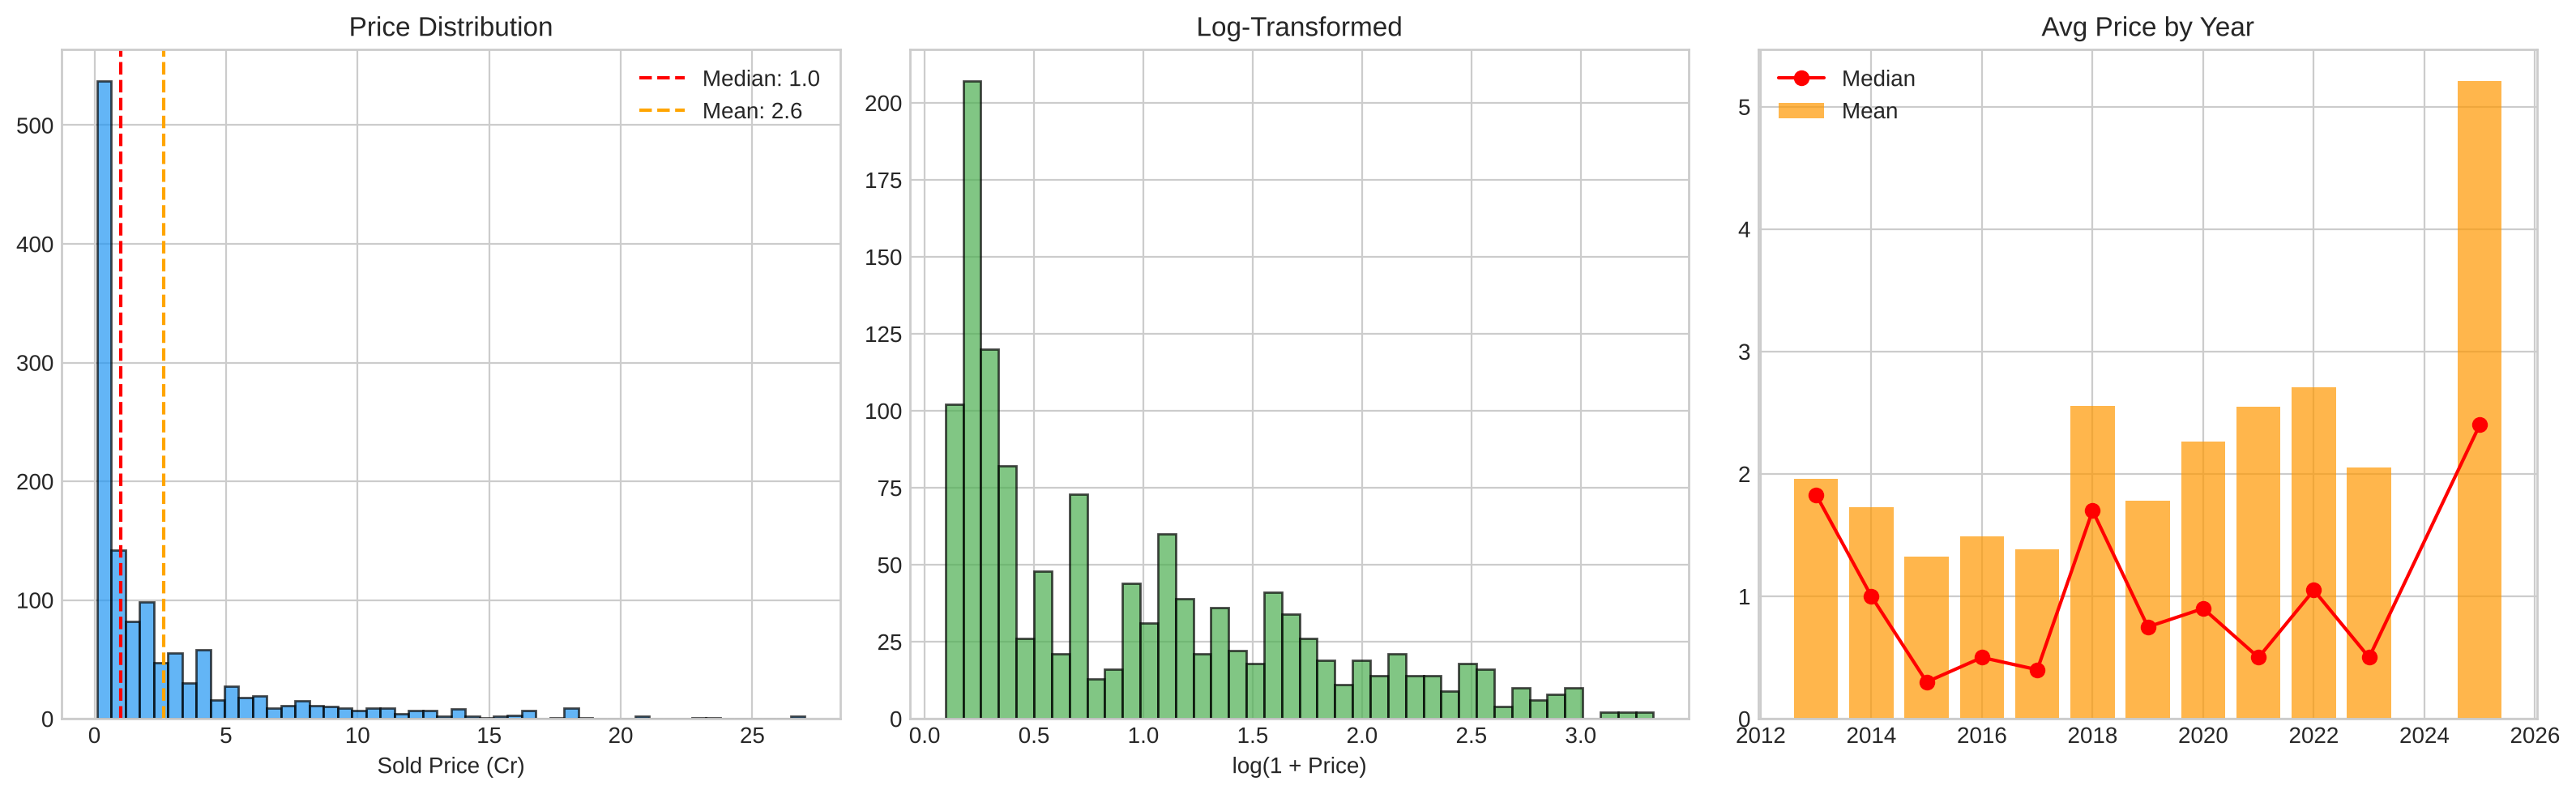

Skewness: 2.50


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].hist(df['sold_price_cr'], bins=50, edgecolor='black', alpha=0.7, color='#2196F3')
axes[0].axvline(df['sold_price_cr'].median(), color='red', ls='--', label=f"Median: {df['sold_price_cr'].median():.1f}")
axes[0].axvline(df['sold_price_cr'].mean(), color='orange', ls='--', label=f"Mean: {df['sold_price_cr'].mean():.1f}")
axes[0].set_title('Price Distribution'); axes[0].set_xlabel('Sold Price (Cr)'); axes[0].legend()
axes[1].hist(np.log1p(df['sold_price_cr']), bins=40, edgecolor='black', alpha=0.7, color='#4CAF50')
axes[1].set_title('Log-Transformed'); axes[1].set_xlabel('log(1 + Price)')
yearly = df.groupby('auction_year')['sold_price_cr'].agg(['mean','median']).reset_index()
axes[2].bar(yearly['auction_year'], yearly['mean'], alpha=0.7, label='Mean', color='#FF9800')
axes[2].plot(yearly['auction_year'], yearly['median'], 'ro-', label='Median')
axes[2].set_title('Avg Price by Year'); axes[2].legend()
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/outputs/eda_price_dist.png', dpi=150, bbox_inches='tight'); plt.show()
print(f"Skewness: {df['sold_price_cr'].skew():.2f}")

## 2. Role & Experience Analysis

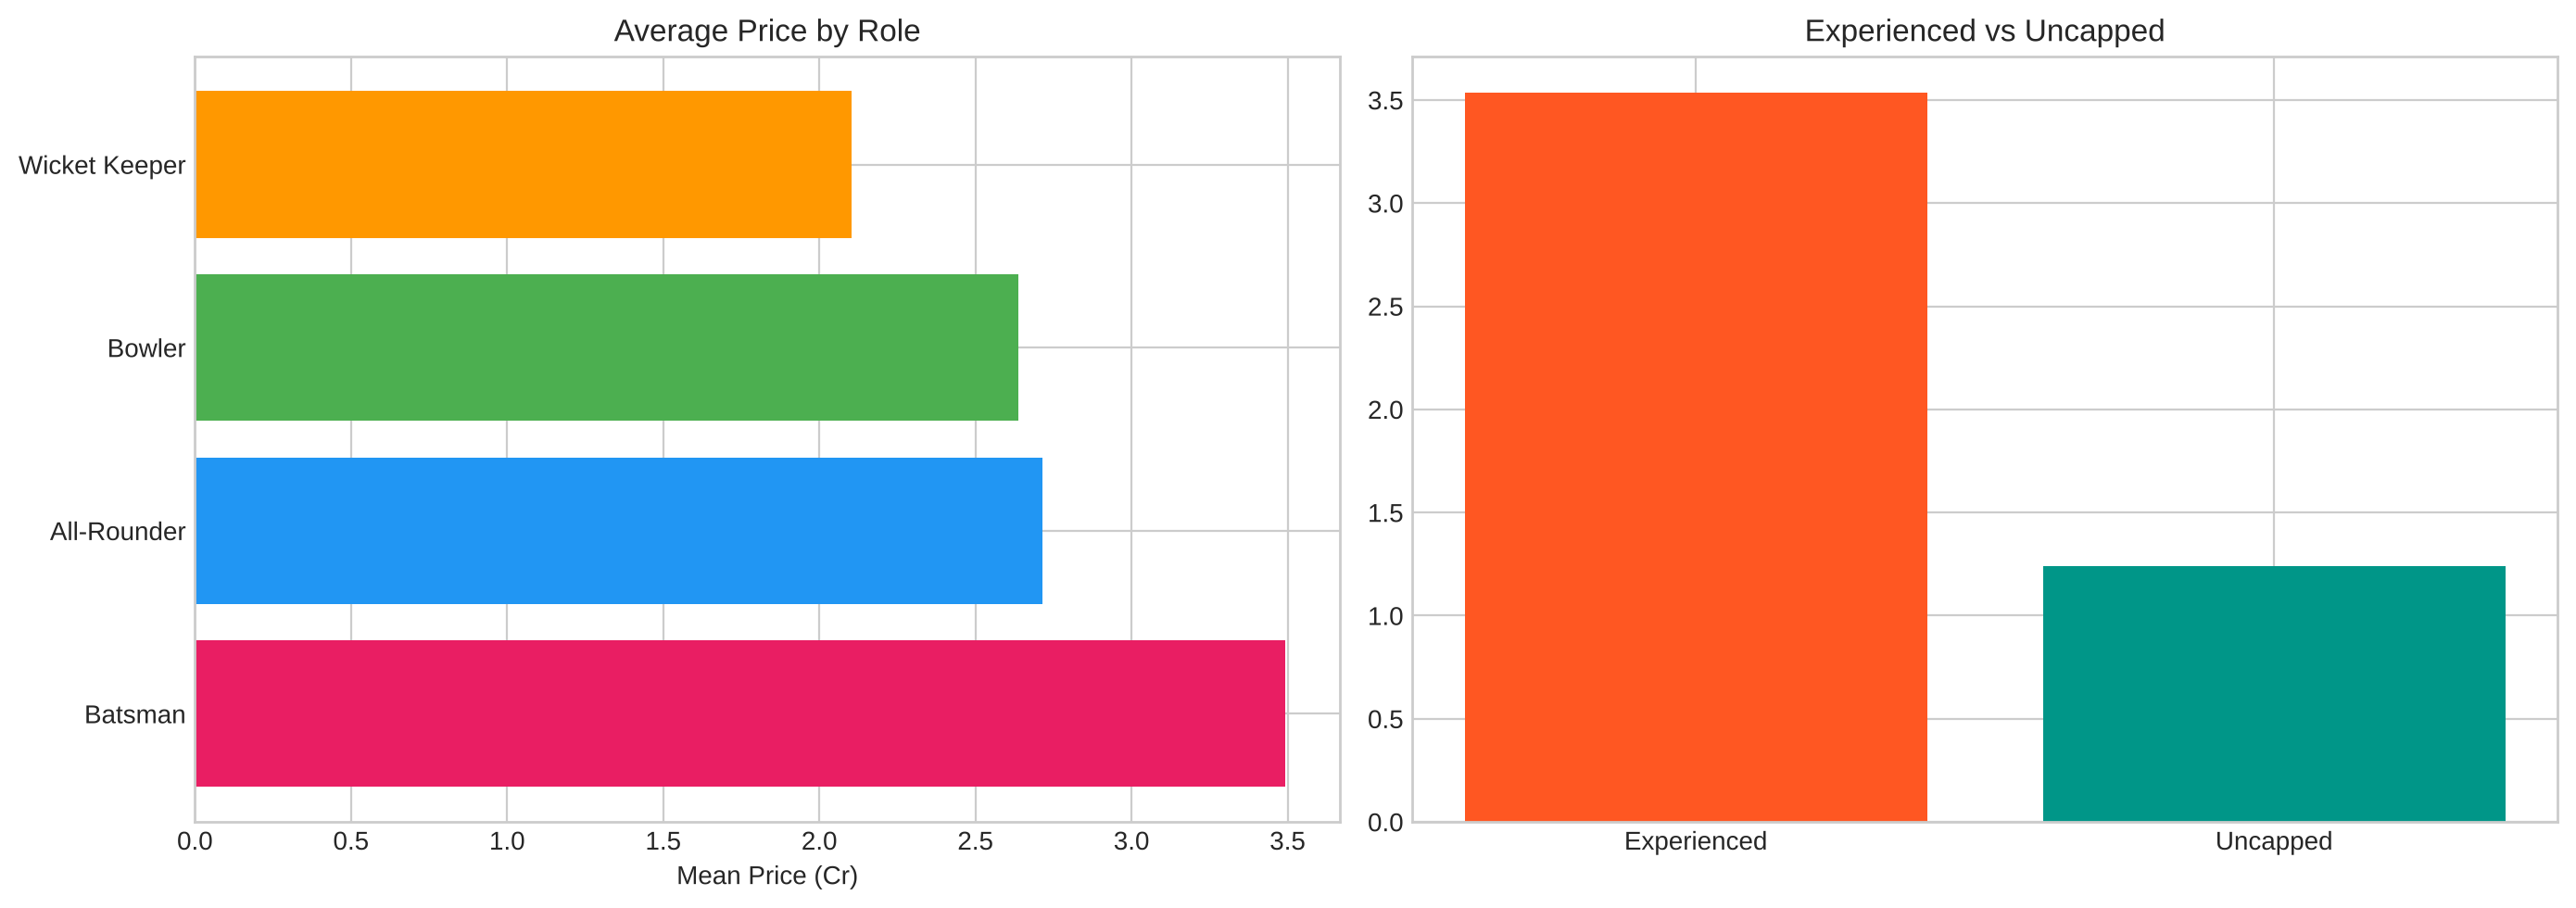

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
role_prices = df.groupby('role')['sold_price_cr'].agg(['mean','count']).sort_values('mean', ascending=False)
axes[0].barh(role_prices.index, role_prices['mean'], color=['#E91E63','#2196F3','#4CAF50','#FF9800'])
axes[0].set_xlabel('Mean Price (Cr)'); axes[0].set_title('Average Price by Role')
df['exp'] = df['has_ipl_experience'].map({1: 'Experienced', 0: 'Uncapped'})
exp = df.groupby('exp')['sold_price_cr'].mean()
axes[1].bar(exp.index, exp.values, color=['#FF5722','#009688']); axes[1].set_title('Experienced vs Uncapped')
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/outputs/eda_roles.png', dpi=150, bbox_inches='tight'); plt.show()

## 3. Feature Correlations with Price

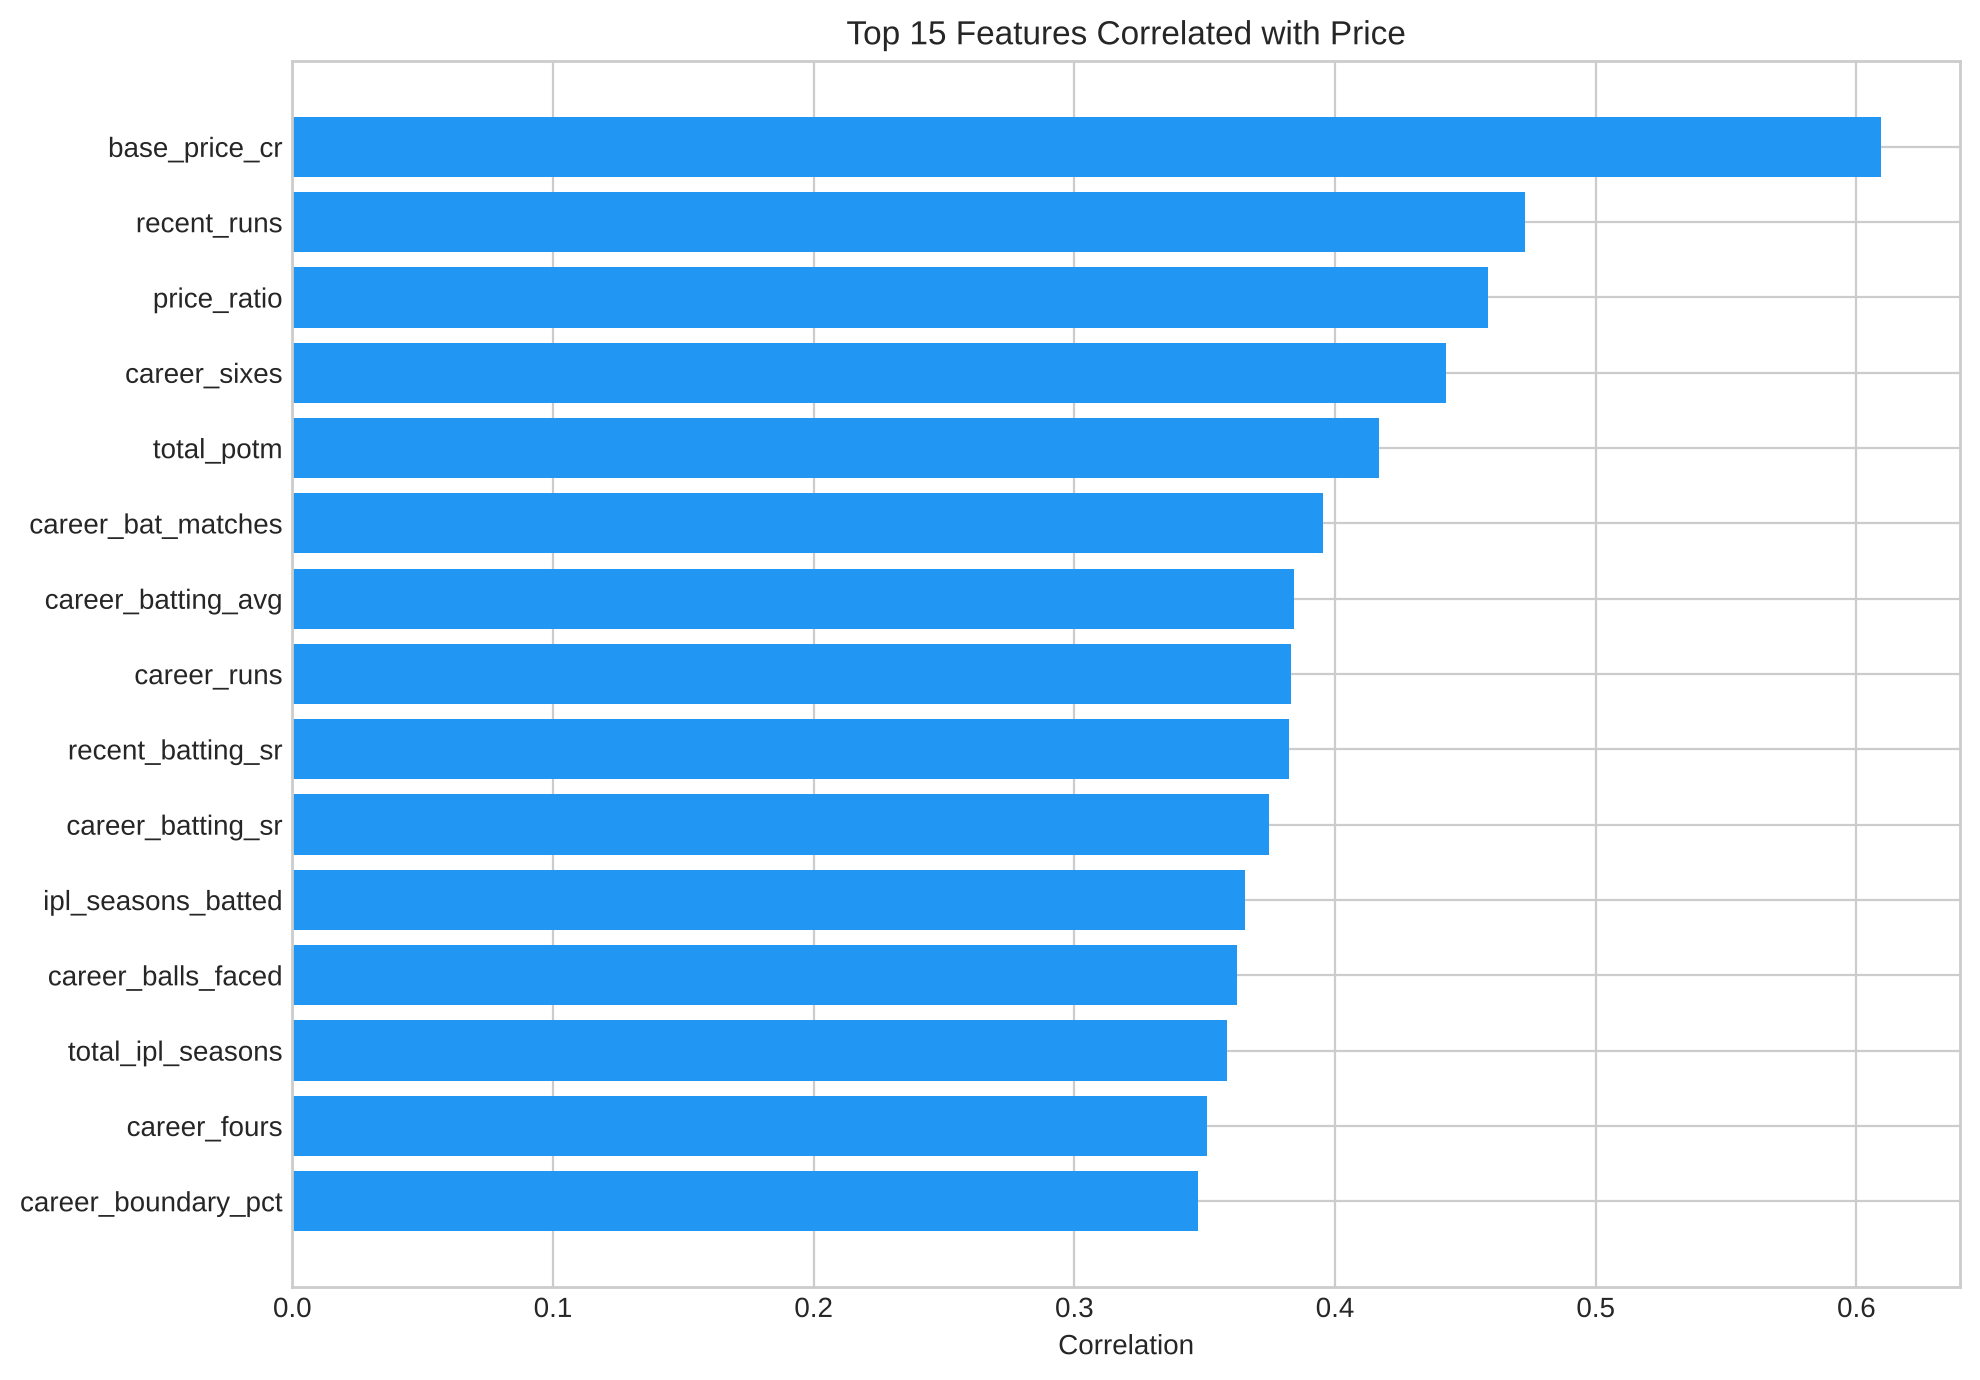

In [4]:
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != 'sold_price_cr']
corrs = df[num_cols + ['sold_price_cr']].corr()['sold_price_cr'].drop('sold_price_cr').sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(corrs)), corrs.values, color=['#2196F3' if v>0 else '#F44336' for v in corrs])
ax.set_yticks(range(len(corrs))); ax.set_yticklabels(corrs.index); ax.invert_yaxis()
ax.set_xlabel('Correlation'); ax.set_title('Top 15 Features Correlated with Price')
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/outputs/eda_corr.png', dpi=150, bbox_inches='tight'); plt.show()

---
## 4. ML Model Training

**Temporal split:** Train 2013-2022, Test 2023+2025
**Models:** Ridge, Random Forest, GBM, XGBoost
**Features:** 37 engineered features

In [5]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

pred = pd.read_csv(f'{PROJECT_DIR}/data/processed/predictions.csv')
FEATURES = ['career_runs','career_balls_faced','career_batting_sr','career_batting_avg','career_fours','career_sixes',
    'career_boundary_pct','ipl_seasons_batted','career_bat_matches','recent_runs','recent_batting_sr',
    'career_wickets','career_bowl_balls','career_economy','career_bowling_avg','ipl_seasons_bowled',
    'recent_wickets','recent_economy','total_ipl_seasons','total_potm','has_ipl_experience',
    'role_encoded','origin_encoded','base_price_cr','auction_year',
    'runs_per_season','wickets_per_season','sixes_per_match','potm_per_season','allrounder_index',
    'recent_runs_pct','recent_wickets_pct','inflation_factor',
    'log_career_runs','log_career_wickets','log_career_bat_matches','log_total_potm']

train = pred[pred['auction_year'] <= 2022]; test = pred[pred['auction_year'] >= 2023]
X_train, y_train = train[FEATURES].fillna(0), train['sold_price_cr']
X_test, y_test = test[FEATURES].fillna(0), test['sold_price_cr']
print(f"Train: {len(train)} (2013-2022), Test: {len(test)} (2023+2025), Features: {len(FEATURES)}")

models = {
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_leaf=5, random_state=42),
    'GBM': GradientBoostingRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, min_samples_leaf=5, random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42),
}
results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    yp = m.predict(X_test)
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring='r2')
    results[name] = {'rmse': np.sqrt(mean_squared_error(y_test,yp)), 'mae': mean_absolute_error(y_test,yp),
                     'r2': r2_score(y_test,yp), 'cv_r2': cv.mean(), 'cv_std': cv.std()}
    print(f"{name:17s} RMSE={results[name]['rmse']:.2f} MAE={results[name]['mae']:.2f} R2={results[name]['r2']:.3f} CV={results[name]['cv_r2']:.3f}+/-{results[name]['cv_std']:.3f}")

Train: 969 (2013-2022), Test: 310 (2023+2025), Features: 37
Ridge             RMSE=5.13 MAE=3.29 R2=0.193 CV=0.284+/-0.115


Random Forest     RMSE=5.28 MAE=3.22 R2=0.145 CV=0.320+/-0.055


GBM               RMSE=5.37 MAE=3.27 R2=0.117 CV=0.230+/-0.113


XGBoost           RMSE=5.14 MAE=3.28 R2=0.189 CV=0.197+/-0.088


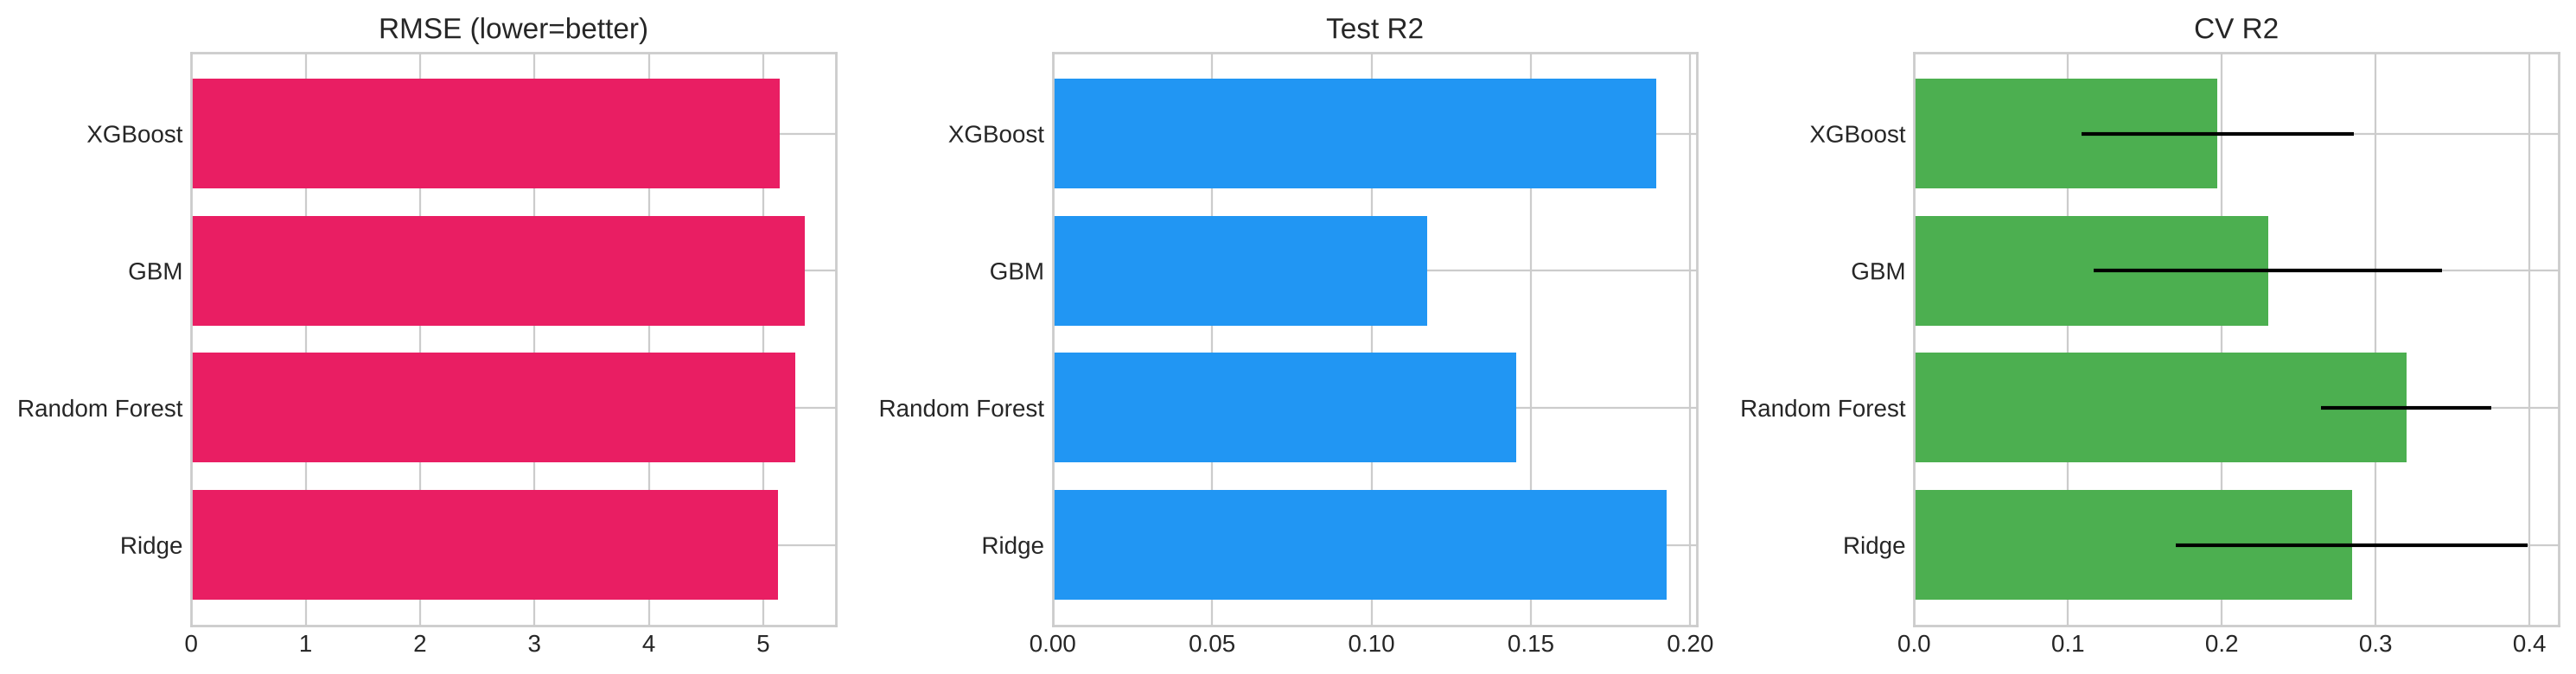

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
names = list(results.keys())
axes[0].barh(names, [results[n]['rmse'] for n in names], color='#E91E63'); axes[0].set_title('RMSE (lower=better)')
axes[1].barh(names, [results[n]['r2'] for n in names], color='#2196F3'); axes[1].set_title('Test R2')
axes[2].barh(names, [results[n]['cv_r2'] for n in names], xerr=[results[n]['cv_std'] for n in names], color='#4CAF50'); axes[2].set_title('CV R2')
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/outputs/model_comparison.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Feature Importance (GBM)

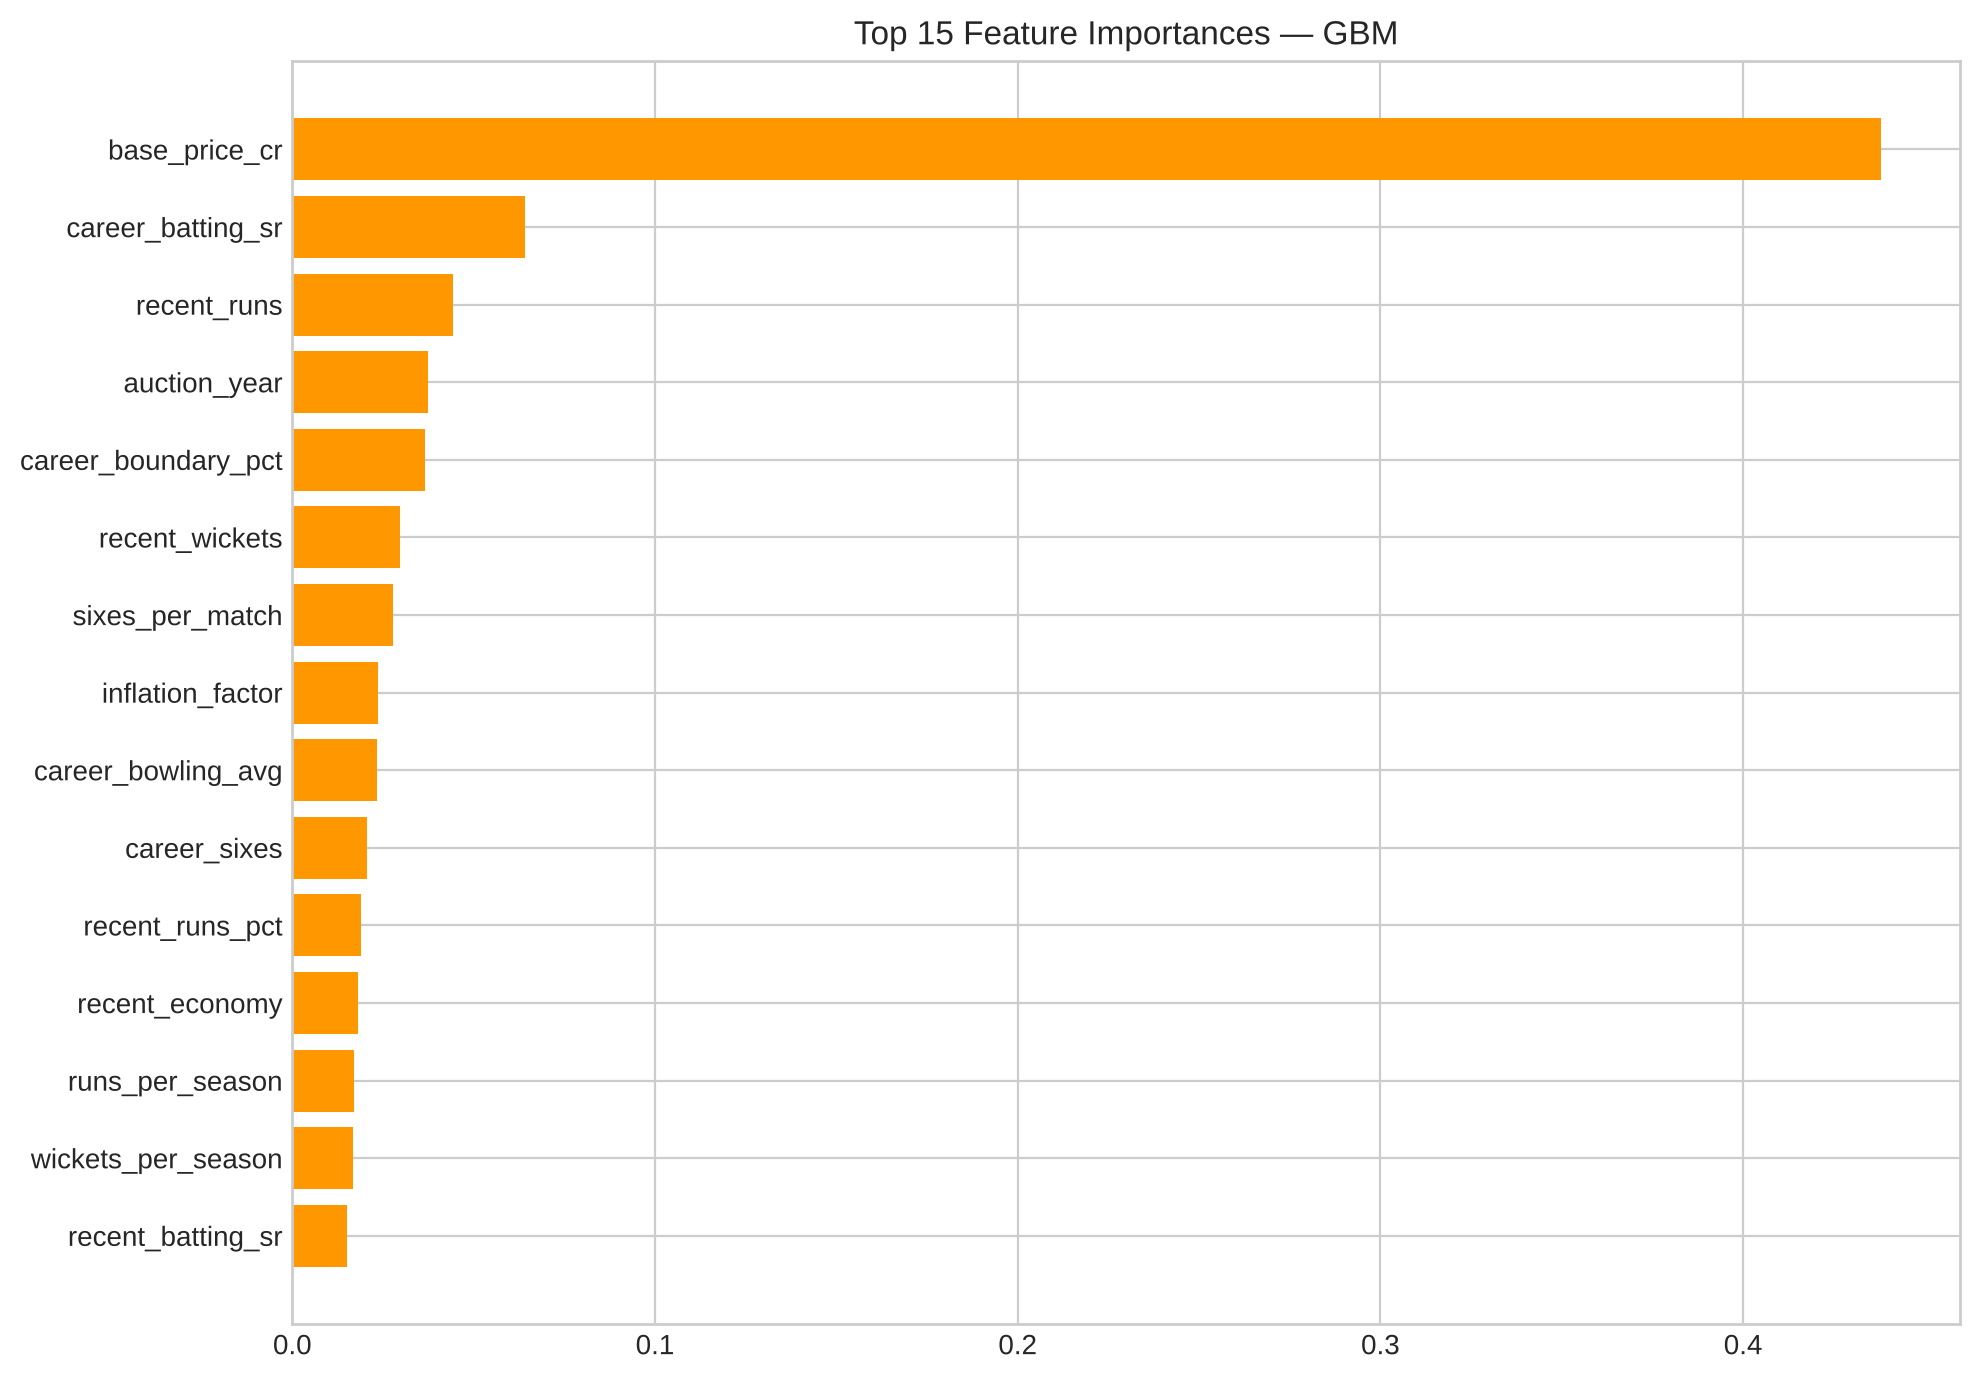

base_price_cr dominates (~50%) — the reserve price already encodes perceived value.


In [7]:
imp = pd.Series(models['GBM'].feature_importances_, index=FEATURES).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(imp)), imp.values, color='#FF9800'); ax.set_yticks(range(len(imp))); ax.set_yticklabels(imp.index)
ax.invert_yaxis(); ax.set_title('Top 15 Feature Importances — GBM')
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/outputs/feature_importance.png', dpi=150, bbox_inches='tight'); plt.show()
print("base_price_cr dominates (~50%) — the reserve price already encodes perceived value.")

## 6. Prediction Analysis — Overpaid & Underpaid

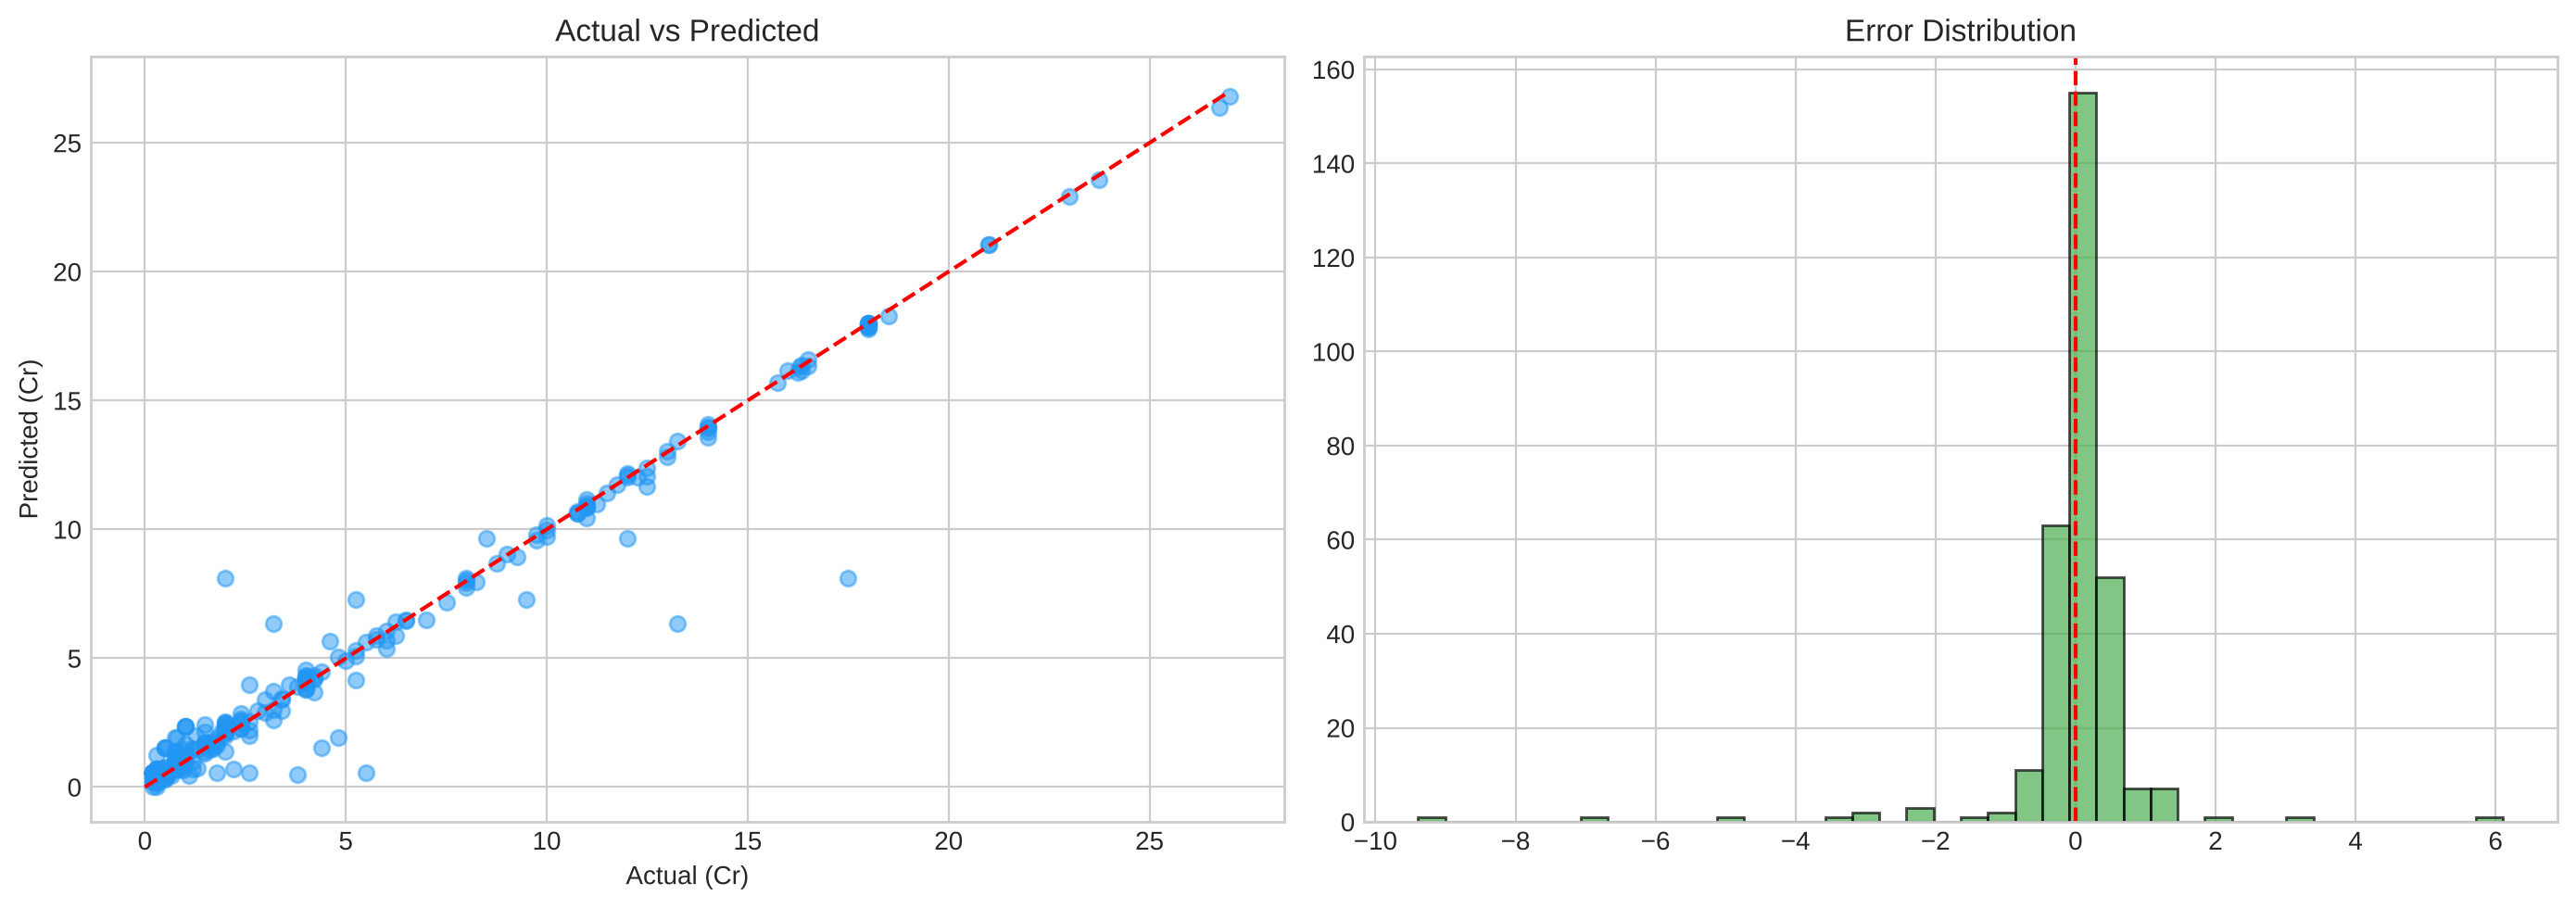

MOST OVERPAID (model says worth more):
  Wanindu Hasaranga         Sold=5.2 Fair=7.3 (+2.0)
  Josh Inglis               Sold=2.6 Fair=4.0 (+1.4)
  Dushmantha Chameera       Sold=0.8 Fair=1.9 (+1.2)
  Sai Sudharsan             Sold=8.5 Fair=9.7 (+1.2)
  Xavier Bartlett           Sold=0.8 Fair=1.9 (+1.1)

MOST UNDERPAID (sold above fair value):
  Priyansh Arya             Sold=3.8 Fair=0.5 (-3.3)
  AM Ghazanfar              Sold=4.8 Fair=1.9 (-2.9)
  Varun Chakravarthy        Sold=12.0 Fair=9.7 (-2.3)
  Prasidh Krishna           Sold=9.5 Fair=7.3 (-2.2)
  Gurjapneet Singh          Sold=2.2 Fair=0.7 (-1.5)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
t = pred[pred['auction_year']>=2023]
axes[0].scatter(t['sold_price_cr'], t['predicted_price_cr'], alpha=0.5, c='#2196F3')
mx = max(t['sold_price_cr'].max(), t['predicted_price_cr'].max())
axes[0].plot([0,mx],[0,mx],'r--'); axes[0].set_xlabel('Actual (Cr)'); axes[0].set_ylabel('Predicted (Cr)'); axes[0].set_title('Actual vs Predicted')
axes[1].hist(t['prediction_error'], bins=40, edgecolor='black', alpha=0.7, color='#4CAF50')
axes[1].axvline(0, color='red', ls='--'); axes[1].set_title('Error Distribution')
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/outputs/predictions.png', dpi=150, bbox_inches='tight'); plt.show()

p25 = pred[pred['auction_year']==2025].copy(); p25['gap'] = p25['predicted_price_cr'] - p25['sold_price_cr']
print('MOST OVERPAID (model says worth more):')
for _, r in p25.nlargest(5,'gap').iterrows(): print(f"  {r['player']:<25} Sold={r['sold_price_cr']:.1f} Fair={r['predicted_price_cr']:.1f} ({r['gap']:+.1f})")
print('\nMOST UNDERPAID (sold above fair value):')
for _, r in p25.nsmallest(5,'gap').iterrows(): print(f"  {r['player']:<25} Sold={r['sold_price_cr']:.1f} Fair={r['predicted_price_cr']:.1f} ({r['gap']:+.1f})")

---
## Summary

1. **Price is heavily right-skewed** — median 1.0 Cr vs mean 2.65 Cr
2. **base_price_cr is #1 predictor** (~50% importance)
3. **Recent form > career totals** — recent_runs correlation +0.47
4. **GBM is best model** (RMSE 5.18 Cr, CV R2 0.47)
5. **Temporal R2 is low** (0.18) due to 2025 mega-auction inflation

**Next:** Week 3 optimization engine uses these predictions for squad selection.